# COCO Image Viewer

- https://gist.github.com/akTwelve
  
This notebook will allow you to view details about a COCO dataset and preview segmentations on annotated images.
Learn more about it at: http://cocodataset.org/

Note: Gist probably won't show the segmentations, but if you run this code in your own Jupyter Notebook, you'll see them.

The rest of the tutorial can be found at: http://www.immersivelimit.com/tutorials/create-coco-annotations-from-scratch

In [1]:
import IPython
import os
import json
import random
import numpy as np
import requests
from io import BytesIO
import base64
from PIL import Image as PILImage
from PIL import ImageDraw as PILImageDraw

In [2]:
image_size = 256


In [3]:
# Load the dataset json
class CocoDataset():
    def __init__(self, annotation_path, image_dir):
        self.annotation_path = annotation_path
        self.image_dir = image_dir
        self.colors = colors = ['blue', 'purple', 'red', 'green', 'orange', 'salmon', 'pink', 'gold',
                                'orchid', 'slateblue', 'limegreen', 'seagreen', 'darkgreen', 'olive',
                               'teal', 'aquamarine', 'steelblue', 'powderblue', 'dodgerblue', 'navy',
                               'magenta', 'sienna', 'maroon']
        
        json_file = open(self.annotation_path)
        self.coco = json.load(json_file)
        json_file.close()
        
        self.process_info()
        self.process_licenses()
        self.process_categories()
        self.process_images()
        self.process_segmentations()
            
        
    def display_info(self):
        print('Dataset Info:')
        print('=============')
        for key, item in self.info.items():
            print('  {}: {}'.format(key, item))
        
        requirements = [['description', str],
                        ['url', str],
                        ['version', str],
                        ['year', int],
                        ['contributor', str],
                        ['date_created', str]]
        for req, req_type in requirements:
            if req not in self.info:
                print('ERROR: {} is missing'.format(req))
            elif type(self.info[req]) != req_type:
                print('ERROR: {} should be type {}'.format(req, str(req_type)))
        print('')

        
    def display_licenses(self):
        print('Licenses:')
        print('=========')
        
        requirements = [['id', int],
                        ['url', str],
                        ['name', str]]
        for license in self.licenses:
            for key, item in license.items():
                print('  {}: {}'.format(key, item))
            for req, req_type in requirements:
                if req not in license:
                    print('ERROR: {} is missing'.format(req))
                elif type(license[req]) != req_type:
                    print('ERROR: {} should be type {}'.format(req, str(req_type)))
            print('')
        print('')
        
    def display_categories(self):
        print('Categories:')
        print('=========')
        for sc_key, sc_val in self.super_categories.items():
            print('  super_category: {}'.format(sc_key))
            for cat_id in sc_val:
                print('    id {}: {}'.format(cat_id, self.categories[cat_id]['name']))
            print('')
    
    def display_image(self, image_id, show_polys=True, show_bbox=True, show_crowds=True, use_url=False):
        print('Image:')
        print('======')
        if image_id == 'random':
            image_id = random.choice(list(self.images.keys()))
        
        # Print the image info
        image = self.images[image_id]
        for key, val in image.items():
            print('  {}: {}'.format(key, val))
            
        # Open the image
        if use_url:
            image_path = image['coco_url']
            response = requests.get(image_path)
            image = PILImage.open(BytesIO(response.content))
            
        else:
            image_path = os.path.join(self.image_dir, image['file_name'])
            image = PILImage.open(image_path)
            
            buffer = BytesIO()
            image.save(buffer, format='PNG')
            buffer.seek(0)
            
            data_uri = base64.b64encode(buffer.read()).decode('ascii')
            image_path = "data:image/png;base64,{0}".format(data_uri)
            
        # Calculate the size and adjusted display size
        max_width = 600
        image_width, image_height = image.size
        adjusted_width = min(image_width, max_width)
        adjusted_ratio = adjusted_width / image_width
        adjusted_height = adjusted_ratio * image_height
        
        # Create list of polygons to be drawn
        polygons = {}
        bbox_polygons = {}
        rle_regions = {}
        poly_colors = {}
        print('  segmentations ({}):'.format(len(self.segmentations[image_id])))
        for i, segm in enumerate(self.segmentations[image_id]):
            polygons_list = []
            if segm['iscrowd'] != 0:
                # Gotta decode the RLE
                px = 0
                x, y = 0, 0
                rle_list = []
                for j, counts in enumerate(segm['segmentation']['counts']):
                    if j % 2 == 0:
                        # Empty pixels
                        px += counts
                    else:
                        # Need to draw on these pixels, since we are drawing in vector form,
                        # we need to draw horizontal lines on the image
                        x_start = trunc(trunc(px / image_height) * adjusted_ratio)
                        y_start = trunc(px % image_height * adjusted_ratio)
                        px += counts
                        x_end = trunc(trunc(px / image_height) * adjusted_ratio)
                        y_end = trunc(px % image_height * adjusted_ratio)
                        if x_end == x_start:
                            # This is only on one line
                            rle_list.append({'x': x_start, 'y': y_start, 'width': 1 , 'height': (y_end - y_start)})
                        if x_end > x_start:
                            # This spans more than one line
                            # Insert top line first
                            rle_list.append({'x': x_start, 'y': y_start, 'width': 1, 'height': (image_height - y_start)})
                            
                            # Insert middle lines if needed
                            lines_spanned = x_end - x_start + 1 # total number of lines spanned
                            full_lines_to_insert = lines_spanned - 2
                            if full_lines_to_insert > 0:
                                full_lines_to_insert = trunc(full_lines_to_insert * adjusted_ratio)
                                rle_list.append({'x': (x_start + 1), 'y': 0, 'width': full_lines_to_insert, 'height': image_height})
                                
                            # Insert bottom line
                            rle_list.append({'x': x_end, 'y': 0, 'width': 1, 'height': y_end})
                if len(rle_list) > 0:
                    rle_regions[segm['id']] = rle_list  
            else:
                # Add the polygon segmentation
                for segmentation_points in segm['segmentation']:
                    segmentation_points = np.multiply(segmentation_points, adjusted_ratio).astype(int)
                    polygons_list.append(str(segmentation_points).lstrip('[').rstrip(']'))
            polygons[segm['id']] = polygons_list
            #
            # if i < len(self.colors):
            #     poly_colors[segm['id']] = self.colors[i] 
            # else:
            #     poly_colors[segm['id']] = 'white'         
            # modified to give the same color for the same cell type
            
            poly_colors[segm['id']] = self.colors[segm['category_id']] #####
            #     
            bbox = segm['bbox']
            bbox_points = [bbox[0], bbox[1], bbox[0] + bbox[2], bbox[1],
                           bbox[0] + bbox[2], bbox[1] + bbox[3], bbox[0], bbox[1] + bbox[3],
                           bbox[0], bbox[1]]
            bbox_points = np.multiply(bbox_points, adjusted_ratio).astype(int)
            bbox_polygons[segm['id']] = str(bbox_points).lstrip('[').rstrip(']')
            
            # Print details
            print('    {}:{}:{}'.format(segm['id'], poly_colors[segm['id']], self.categories[segm['category_id']]))  ########
        
        
        
        # Draw segmentation polygons on image
        html  = '<div class="container" style="position:relative;">'
        html += '<img src="{}" style="position:relative;top:0px;left:0px;width:{}px;">'.format(image_path, adjusted_width)
        html += '<div class="svgclass"><svg width="{}" height="{}">'.format(adjusted_width, adjusted_height)
        
        if show_polys:
            for seg_id, points_list in polygons.items():
                fill_color = poly_colors[seg_id]
                stroke_color = poly_colors[seg_id]
                for points in points_list:
                    html += '<polygon points="{}" style="fill:{}; stroke:{}; stroke-width:1; fill-opacity:0.5" />'.format(points, fill_color, stroke_color)
        
        if show_crowds:
            for seg_id, rect_list in rle_regions.items():
                fill_color = poly_colors[seg_id]
                stroke_color = poly_colors[seg_id]
                for rect_def in rect_list:
                    x, y = rect_def['x'], rect_def['y']
                    w, h = rect_def['width'], rect_def['height']
                    html += '<rect x="{}" y="{}" width="{}" height="{}" style="fill:{}; stroke:{}; stroke-width:1; fill-opacity:0.5; stroke-opacity:0.5" />'.format(x, y, w, h, fill_color, stroke_color)
            
        if show_bbox:
            for seg_id, points in bbox_polygons.items():
                fill_color = poly_colors[seg_id]
                stroke_color = poly_colors[seg_id]
                html += '<polygon points="{}" style="fill:{}; stroke:{}; stroke-width:1; fill-opacity:0" />'.format(points, fill_color, stroke_color)
                
        html += '</svg></div>'
        html += '</div>'
        html += '<style>'
        html += '.svgclass { position:absolute; top:0px; left:0px;}'
        html += '</style>'
        return html
       
    def process_info(self):
        self.info = self.coco['info']
    
    def process_licenses(self):
        self.licenses = self.coco['licenses']
    
    def process_categories(self):
        self.categories = {}
        self.super_categories = {}
        for category in self.coco['categories']:
            cat_id = category['id']
            super_category = category['supercategory']
            
            # Add category to the categories dict
            if cat_id not in self.categories:
                self.categories[cat_id] = category
            else:
                print("ERROR: Skipping duplicate category id: {}".format(category))

            # Add category to super_categories dict
            if super_category not in self.super_categories:
                self.super_categories[super_category] = {cat_id} # Create a new set with the category id
            else:
                self.super_categories[super_category] |= {cat_id} # Add category id to the set
                
    def process_images(self):
        self.images = {}
        for image in self.coco['images']:
            image_id = image['id']
            if image_id in self.images:
                print("ERROR: Skipping duplicate image id: {}".format(image))
            else:
                self.images[image_id] = image
                
    def process_segmentations(self):
        self.segmentations = {}
        for segmentation in self.coco['annotations']:
            image_id = segmentation['image_id']
            if image_id not in self.segmentations:
                self.segmentations[image_id] = []
            self.segmentations[image_id].append(segmentation)

In [4]:
annotation_path = f'./dataset/png_{image_size}/image/train/train_annot_coco_{image_size}.json'

image_dir = f'./dataset/png_{image_size}/image/train'
coco_dataset = CocoDataset(annotation_path, image_dir)
coco_dataset.display_info()
coco_dataset.display_licenses()
coco_dataset.display_categories()

Dataset Info:
  description: Hardwood Cross Section
  url: https://test
  version: 1.00
  year: 2024
  contributor: montcypres
ERROR: date_created is missing

Licenses:

Categories:
  super_category: stuff
    id 0: stuff

  super_category: vessel
    id 1: vessel

  super_category: ray
    id 2: ray

  super_category: fiber
    id 3: fiber

  super_category: parenchyma
    id 4: parenchyma



Image:
  file_name: 0016_burspi2_02_img.png
  height: 256
  width: 256
  id: 0
  date_captured: 2025 Izumi 
  segmentations (50):
    0:purple:{'supercategory': 'vessel', 'id': 1, 'name': 'vessel'}
    1:purple:{'supercategory': 'vessel', 'id': 1, 'name': 'vessel'}
    2:purple:{'supercategory': 'vessel', 'id': 1, 'name': 'vessel'}
    3:purple:{'supercategory': 'vessel', 'id': 1, 'name': 'vessel'}
    4:purple:{'supercategory': 'vessel', 'id': 1, 'name': 'vessel'}
    5:purple:{'supercategory': 'vessel', 'id': 1, 'name': 'vessel'}
    6:purple:{'supercategory': 'vessel', 'id': 1, 'name': 'vessel'}
    7:purple:{'supercategory': 'vessel', 'id': 1, 'name': 'vessel'}
    8:purple:{'supercategory': 'vessel', 'id': 1, 'name': 'vessel'}
    9:purple:{'supercategory': 'vessel', 'id': 1, 'name': 'vessel'}
    10:green:{'supercategory': 'fiber', 'id': 3, 'name': 'fiber'}
    11:green:{'supercategory': 'fiber', 'id': 3, 'name': 'fiber'}
    12:green:{'supercategory': 'fiber', 'id': 3, 'name': '


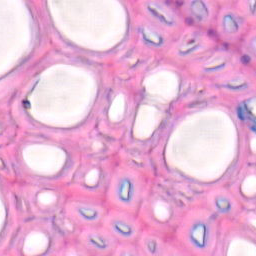

In [5]:
html = coco_dataset.display_image(0, use_url=False)
IPython.display.HTML(html)

In [6]:
#html = coco_dataset.display_image(1, use_url=False)
#html = coco_dataset.display_image(0, show_bbox=False, show_polys=False, show_crowds=False)
#IPython.display.HTML(html)
#IPython.display.HTML(html)

# Sample Annotations JSON
Below are the contents of 'sample_annotations.json'.

In [7]:
# with open(annotation_path) as json_file:
#     lines = json_file.readlines()
# for line in lines:
#     print(line)

import pandas as pd
jsonfile=annotation_path
with open(jsonfile, encoding='utf-8') as f:
    d = json.load(f)
# normalization
df=pd.json_normalize(d)

<Figure size 1000x1000 with 0 Axes>

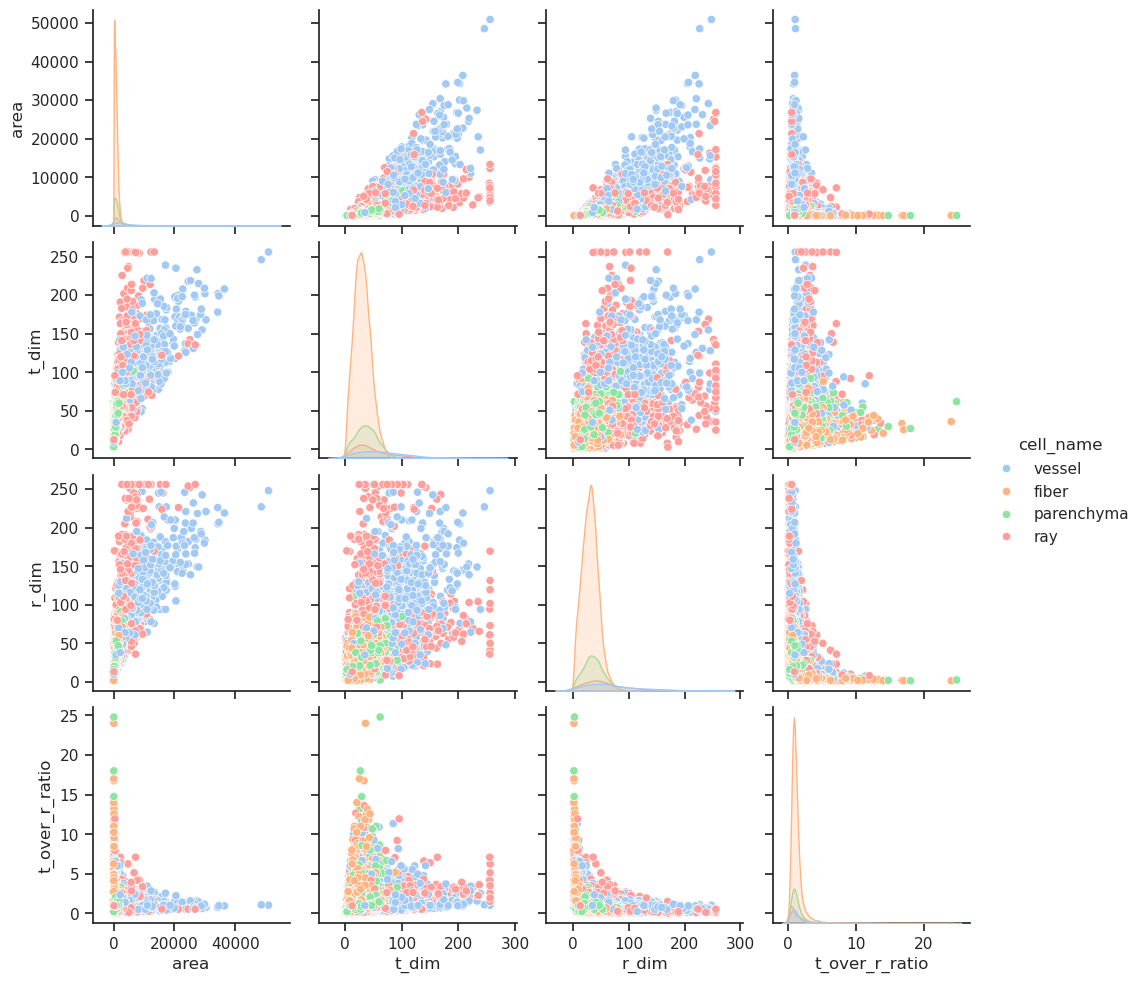

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
areas = []
cell_ids = []
t_dims = []
r_dims = []
for i in range(len(df["annotations"][0])):
    areas.append(df["annotations"][0][i]['area'])
    cell_ids.append(df["annotations"][0][i]['category_id'])
    t_dims.append(df["annotations"][0][i]['bbox'][2])
    r_dims.append(df["annotations"][0][i]['bbox'][3])    

df1=pd.DataFrame()
df1['cell_id']= cell_ids
df1['area']= areas
df1['t_dim']= t_dims
df1['r_dim']= r_dims
df1['t_over_r_ratio'] = df1['t_dim']/df1['r_dim']

cell_types = ['stuff', 'vessel', 'ray', 'fiber', 'parenchyma']
cell_name = [cell_types[n] for n in cell_ids]
df1['cell_name']= cell_name
plt.figure(figsize=(10, 10)) 
sns.set_theme(style="ticks", palette="pastel")
sns.pairplot(df1, vars=['area', 't_dim', 'r_dim', 't_over_r_ratio'], hue="cell_name")
plt.show()

In [9]:
df1.describe()

,cell_id,area,t_dim,r_dim,t_over_r_ratio
count,23162.000000,23162.000000,23162.000000,23162.000000,23162.000000
mean,2.944046,1108.018910,35.234932,36.361476,1.227185
std,0.698475,1980.815576,23.930123,26.163310,1.068845
min,1.000000,1.250000,1.500000,1.500000,0.017647
25%,3.000000,308.000000,20.000000,21.000000,0.675000
50%,3.000000,685.500000,31.500000,32.000000,0.980000
75%,3.000000,1221.687500,44.000000,44.000000,1.419246
max,4.000000,50937.500000,256.000000,256.000000,24.800000


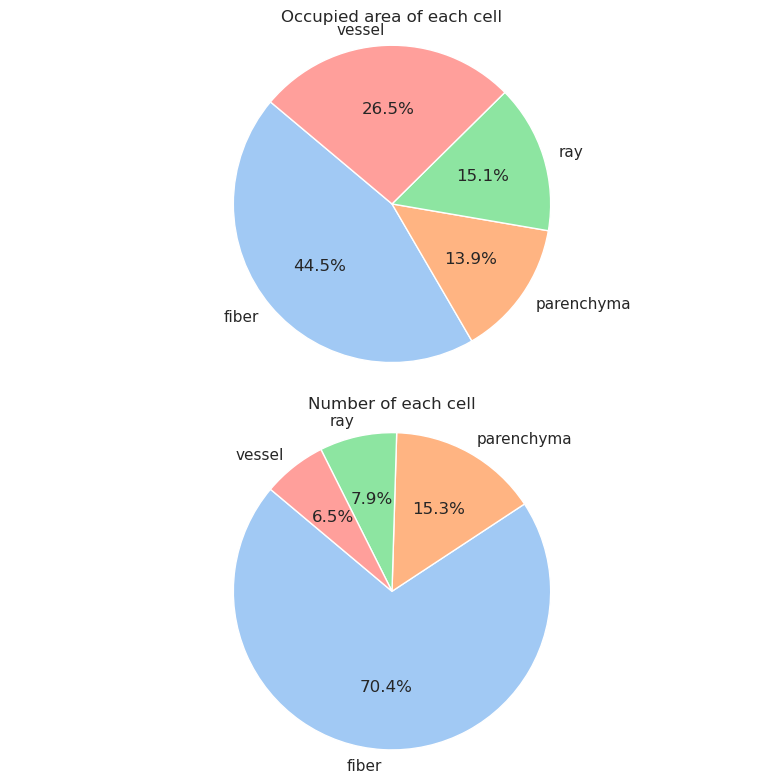

In [10]:
# Comparison of the total area occupied with 4 types
category_totals = df1.groupby('cell_name')['area'].sum().reset_index()

labels = category_totals['cell_name']
sizes = category_totals['area']
u, counts = np.unique(df1['cell_name'], return_counts=True)
colors = sns.color_palette('pastel')[0:len(labels)]

items = [labels.values, labels]
amount = [sizes.values, counts]
comment = ['Occupied area of each cell','Number of each cell']

fig, ax = plt.subplots(2,1,figsize=(8,8))
for j in range(2):
    ax[j].pie(amount[j], labels=items[j], colors=colors, autopct='%1.1f%%', startangle=140)
    ax[j].axis('equal') 
    ax[j].set_title(comment[j])
plt.tight_layout()
plt.show()

The end of script